# Correlación entre las tareas de un ensayo

Verificación del bloque «Generador: factores de correlación» (`docs/Generador_de_datos.docx`, sección 2).
`muestrear_ensayo` correlaciona las tareas de una ejecución con una cópula gaussiana: ρ = 0,5 entre las cuatro
tareas del analista (supuesto S04, con sensibilidad de 0,3 y 0,7) e independencia de la idoneidad y la corrida,
que son del equipo (hoja «Correlaciones» del Excel). Este cuaderno:

- compara la matriz de correlación de rangos obtenida con la objetivo, con la cópula y con el método de Iman y
  Conover (1982), en los doce ensayos y con los tres valores de ρ;
- mide cuánto cambia la duración de cada ensayo, y cómo queda su dispersión frente a la de la fuente con las dos
  formas λ del cuaderno 01;
- calcula el indicador V2 en una mezcla de ensayos como la del escenario base y prueba su tolerancia en datasets
  chicos, con la mezcla de niveles de analista y la idoneidad del sistema.

Todavía no incluye la preparación ni la idoneidad del sistema, cuyos tres puntos se fijan después: en estos
ensayos valen cero, así que sus pares quedan fuera de las comparaciones, salvo en la prueba de tolerancia de V2,
que usa los tres puntos de ensayo de `tests/test_duraciones.py`. Usa la tabla `distancia_a_la_fuente.csv` del
cuaderno 01. Guarda la figura en `resultados/figuras/` y las tablas en `resultados/tablas/`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
from src.generador import correlacion as co, duraciones as du, parametros, registro

SEMILLA = 2026
N = 200_000                  # ejecuciones simuladas en cada comparación
RHOS = [0.3, 0.5, 0.7]       # supuesto S04: propuesta y sensibilidad
ENSAYO, N_SOLUCIONES = "M02", 4
TAREAS = registro.TAREAS
TABLAS = RAIZ / "resultados" / "tablas"
FIGURA = RAIZ / "resultados" / "figuras" / "correlacion_tareas_M02.png"

catalogo = parametros.cargar_hoja("Catálogo").set_index("ID")
fuente = pd.read_csv(TABLAS / "distancia_a_la_fuente.csv").set_index("Ensayo")   # del cuaderno 01
hoja = parametros.cargar_hoja("Duraciones")
CAMPO = {"Preparación de muestra": "t_preparacion", "Montaje del equipo": "t_montaje",
         "Corrida": "t_corrida", "Procesamiento de datos": "t_procesamiento"}
hoja = hoja[hoja["Tarea"].isin(list(CAMPO))].set_index(["Técnica", "Tarea"]).sort_index()


def forma_propuesta(metodo):
    """λ = 1 en las tareas triangulares y λ = 0 en las que la fuente da uniformes (la misma del cuaderno 01)."""
    tecnica = catalogo.at[metodo, "Técnica"]
    return {CAMPO[t]: 0.0 if str(hoja.loc[(tecnica, t), "Distribución original"]).startswith("U") else 1.0
            for t in CAMPO}


objetivo = co.matriz_objetivo()
objetivo

,t_prep_sistema,t_idoneidad,t_preparacion,t_montaje,t_corrida,t_procesamiento
t_prep_sistema,1.0,0.0,0.5,0.5,0.0,0.5
t_idoneidad,0.0,1.0,0.0,0.0,0.0,0.0
t_preparacion,0.5,0.0,1.0,0.5,0.0,0.5
t_montaje,0.5,0.0,0.5,1.0,0.0,0.5
t_corrida,0.0,0.0,0.0,0.0,1.0,0.0
t_procesamiento,0.5,0.0,0.5,0.5,0.0,1.0


## La matriz de la normal

La cópula usa normales con correlación r = 2 sen(πρ/6), que dan exactamente la correlación de rangos ρ
(Clemen y Reilly, 1999, p. 211). Con ρ = 0,5, r = 0,518; sin la conversión, la correlación de rangos quedaría
en 0,483.

In [2]:
pd.DataFrame(co.rho_normal(objetivo), index=objetivo.index, columns=objetivo.columns).round(4)

,t_prep_sistema,t_idoneidad,t_preparacion,t_montaje,t_corrida,t_procesamiento
t_prep_sistema,1.0000,0.0,0.5176,0.5176,0.0,0.5176
t_idoneidad,0.0000,1.0,0.0000,0.0000,0.0,0.0000
t_preparacion,0.5176,0.0,1.0000,0.5176,0.0,0.5176
t_montaje,0.5176,0.0,0.5176,1.0000,0.0,0.5176
t_corrida,0.0000,0.0,0.0000,0.0000,1.0,0.0000
t_procesamiento,0.5176,0.0,0.5176,0.5176,0.0,1.0000


## Matriz obtenida frente a la objetivo

Sustancias relacionadas por HPLC (M02), con cuatro soluciones y un analista intermedio. «Cópula» es
`muestrear_ensayo` con la matriz objetivo; «Iman y Conover», las mismas tareas sacadas independientes y
reordenadas con `inducir_correlacion`, que no cambia sus valores; «Independientes», sin correlación, que es como
el cuaderno 01 las compara con la fuente.

In [3]:
copula = du.muestrear_ensayo(ENSAYO, N_SOLUCIONES, n=N, rng=SEMILLA, correlacion=objetivo)
independientes = du.muestrear_ensayo(ENSAYO, N_SOLUCIONES, n=N, rng=SEMILLA)
reordenadas = co.inducir_correlacion(independientes[TAREAS], objetivo, rng=SEMILLA)


def obtenida(datos, nombre):
    return co.comparar(co.correlacion_rangos(datos), objetivo).rename(columns={"obtenida": nombre}).drop(columns="diferencia")


comparacion = (obtenida(copula[TAREAS], "Cópula")
               .merge(obtenida(reordenadas, "Iman y Conover"), on=["variable_1", "variable_2", "objetivo"])
               .merge(obtenida(independientes[TAREAS], "Independientes"), on=["variable_1", "variable_2", "objetivo"]))
comparacion.to_csv(TABLAS / "correlacion_objetivo_vs_obtenida.csv", index=False)
print("Error máximo:", {k: round((comparacion[k] - comparacion["objetivo"]).abs().max(), 4)
                        for k in ("Cópula", "Iman y Conover", "Independientes")})
comparacion.round(3)

Error máximo: {'Cópula': np.float64(0.0035), 'Iman y Conover': np.float64(0.0011), 'Independientes': np.float64(0.499)}


,variable_1,variable_2,objetivo,Cópula,Iman y Conover,Independientes
0,t_preparacion,t_montaje,0.5,0.496,0.500,0.001
1,t_preparacion,t_corrida,0.0,0.002,-0.000,0.002
2,t_preparacion,t_procesamiento,0.5,0.500,0.500,0.001
3,t_montaje,t_corrida,0.0,0.001,-0.001,0.003
4,t_montaje,t_procesamiento,0.5,0.499,0.500,0.004
5,t_corrida,t_procesamiento,0.0,-0.001,-0.000,-0.001


## Los doce ensayos y los tres valores de ρ

Cada ensayo con el máximo de soluciones de su complejidad, como en el cuaderno 01, y una semilla distinta por
ensayo. El error es la mayor diferencia, en valor absoluto, entre la correlación obtenida y la objetivo en los
pares de tareas que varían. La correlación de rangos solo depende del orden de los valores, así que el error no
depende de las distribuciones de las tareas: con la misma semilla saldría igual en los doce ensayos.

In [4]:
def resumen(d):
    return {"Media": d.mean(), "Desviación": d.std(), "P5": d.quantile(0.05), "P50": d.median(), "P95": d.quantile(0.95)}


errores, efecto = [], []
for k, metodo in enumerate(catalogo.index):
    n_sol, semilla = int(catalogo.at[metodo, "Soluciones máx"]), SEMILLA + k
    clave = {"Ensayo": metodo, "Técnica": catalogo.at[metodo, "Técnica"], "Soluciones": n_sol}
    base = du.muestrear_ensayo(metodo, n_sol, n=N, rng=semilla)
    efecto.append({**clave, "ρ": "sin", **resumen(base["duracion_simulada"])})
    for rho in RHOS:
        m = co.matriz_objetivo(rho)
        t = du.muestrear_ensayo(metodo, n_sol, n=N, rng=semilla, correlacion=m)
        r = co.inducir_correlacion(base[TAREAS], m, rng=semilla)
        errores.append({**clave, "ρ": rho,
                        "Error, cópula": co.error_maximo(co.correlacion_rangos(t[TAREAS]), m),
                        "Error, Iman y Conover": co.error_maximo(co.correlacion_rangos(r), m)})
        efecto.append({**clave, "ρ": rho, **resumen(t["duracion_simulada"])})
errores, efecto = pd.DataFrame(errores), pd.DataFrame(efecto)
errores.to_csv(TABLAS / "correlacion_error_maximo.csv", index=False)
efecto.to_csv(TABLAS / "correlacion_efecto_en_la_duracion.csv", index=False)
errores.groupby("ρ")[["Error, cópula", "Error, Iman y Conover"]].agg(["mean", "max"]).round(4)

Error, cópula         Error, Iman y Conover        
             mean     max                  mean     max
ρ                                                      
0.3        0.0034  0.0051                0.0011  0.0016
0.5        0.0030  0.0041                0.0011  0.0015
0.7        0.0024  0.0035                0.0010  0.0016

## Efecto en la duración

La media de la duración no cambia, porque es una suma de tareas; la dispersión sí crece, y más en los ensayos
en que la varianza se reparte entre varias tareas del analista: si una sola tarea pesa casi toda, como la
preparación en M02, correlacionarla con las demás cambia poco. La tabla da, frente a las tareas independientes,
el cambio relativo de la media, de la desviación estándar y del percentil 95, y el del percentil 95 en minutos.

In [5]:
sin = efecto[efecto["ρ"].eq("sin")].set_index("Ensayo")
cambio = sin[["Técnica", "Soluciones", "Media", "Desviación"]].rename(
    columns={"Media": "Media sin correlación", "Desviación": "Desviación sin correlación"})
for rho in RHOS:
    con = efecto[efecto["ρ"].eq(rho)].set_index("Ensayo")
    cambio[f"Media, ρ = {rho}"] = con["Media"] / sin["Media"] - 1
    cambio[f"Desviación, ρ = {rho}"] = con["Desviación"] / sin["Desviación"] - 1
    cambio[f"P95, ρ = {rho}"] = con["P95"] / sin["P95"] - 1
    cambio[f"P95, ρ = {rho} (min)"] = con["P95"] - sin["P95"]
cambio.round(3)

,Técnica,Soluciones,Media sin correlación,Desviación sin correlación,"Media, ρ = 0.3","Desviación, ρ = 0.3","P95, ρ = 0.3","P95, ρ = 0.3 (min)","Media, ρ = 0.5","Desviación, ρ = 0.5","P95, ρ = 0.5","P95, ρ = 0.5 (min)","Media, ρ = 0.7","Desviación, ρ = 0.7","P95, ρ = 0.7","P95, ρ = 0.7 (min)"
Ensayo,,,,,,,,,,,,,,,,
M01,HPLC,2,204.346,36.524,-0.001,0.069,0.015,3.905,-0.001,0.115,0.026,6.827,-0.001,0.158,0.036,9.494
M02,HPLC,4,385.956,72.068,0.000,0.036,0.007,3.566,0.000,0.060,0.013,6.775,0.000,0.083,0.019,9.507
M03,GC,2,103.889,13.292,0.000,0.215,0.043,5.497,0.000,0.340,0.069,8.828,0.000,0.452,0.093,11.872
M04,GC,4,153.683,22.343,0.000,0.145,0.032,6.298,0.000,0.230,0.051,9.917,0.000,0.309,0.068,13.164
M05,PSA,2,50.704,8.194,-0.001,0.199,0.046,2.963,-0.001,0.315,0.073,4.713,-0.000,0.418,0.098,6.330
M06,PSA,4,74.924,12.610,-0.000,0.157,0.036,3.506,0.000,0.250,0.057,5.580,0.000,0.335,0.077,7.529
M07,KF,4,69.708,17.628,0.000,0.105,0.033,3.368,0.001,0.167,0.051,5.154,0.001,0.224,0.068,6.895
M08,KF,6,108.522,25.818,-0.001,0.068,0.018,2.747,-0.001,0.113,0.030,4.751,-0.002,0.155,0.042,6.616
M09,DSC,2,65.912,10.855,-0.001,0.101,0.023,1.940,-0.001,0.162,0.038,3.228,-0.000,0.219,0.052,4.418


## Dispersión frente a la fuente, con las dos formas

La fuente da una distribución por tarea (Costigliola et al., 2017, Tabla 3) y no dice nada de su dependencia, así
que el cuaderno 01 calcula su dispersión con las tareas independientes y compara con ella dos formas: λ = 4 y la
propuesta de la sección 1.10 (λ = 1, y λ = 0 en las tareas uniformes). La tabla da la desviación estándar de la
duración con cada forma y cada ρ como diferencia relativa con la de la fuente (`distancia_a_la_fuente.csv`), y la
última fila, el promedio de las diferencias absolutas. Con λ = 4 las tareas son más angostas que las de la fuente
y la correlación compensa esa diferencia; con la propuesta, la dispersión ya queda cerca de la fuente y la
correlación la lleva por encima. Las columnas sin correlación se vuelven a simular aquí, con 200 000 ejecuciones y
las mismas semillas que las correlacionadas, así que difieren un poco de las del cuaderno 01, que usa 400 000.

In [6]:
FORMAS = {"λ = 4": lambda metodo: du.FORMA_PERT, "Propuesta": forma_propuesta}
filas = []
for k, metodo in enumerate(catalogo.index):
    n_sol, semilla = int(catalogo.at[metodo, "Soluciones máx"]), SEMILLA + k
    for nombre, forma in FORMAS.items():
        for rho in [None, *RHOS]:
            d = du.muestrear_ensayo(metodo, n_sol, n=N, rng=semilla, forma=forma(metodo), correlacion=rho)["duracion_simulada"]
            filas.append({"Ensayo": metodo, "Forma": nombre, "ρ": "sin" if rho is None else rho,
                          "Media": d.mean(), "Desviación": d.std(),
                          "Media frente a la fuente": d.mean() / fuente.at[metodo, "Media fuente"] - 1,
                          "Desviación frente a la fuente": d.std() / fuente.at[metodo, "Desviación fuente"] - 1})
frente = pd.DataFrame(filas)
frente.to_csv(TABLAS / "correlacion_frente_a_la_fuente.csv", index=False)
tabla = frente.pivot_table(index="Ensayo", columns=["Forma", "ρ"], values="Desviación frente a la fuente", sort=False)
tabla.loc["Promedio de |diferencia|"] = tabla.abs().mean()
tabla.round(3)

Forma                     λ = 4                      Propuesta                \
ρ                           sin    0.3    0.5    0.7       sin    0.3    0.5   
Ensayo                                                                         
M01                      -0.096 -0.033  0.008  0.047     0.208  0.293  0.348   
M02                      -0.097 -0.065 -0.043 -0.022     0.209  0.251  0.280   
M03                      -0.205 -0.034  0.065  0.155     0.129  0.376  0.518   
M04                      -0.216 -0.102 -0.036  0.026     0.123  0.283  0.378   
M05                      -0.294 -0.154 -0.072  0.001     0.048  0.247  0.364   
M06                      -0.269 -0.154 -0.086 -0.024     0.075  0.242  0.341   
M07                      -0.200 -0.116 -0.067 -0.021     0.126  0.237  0.302   
M08                      -0.199 -0.144 -0.108 -0.074     0.134  0.207  0.254   
M09                      -0.245 -0.169 -0.123 -0.080     0.089  0.191  0.253   
M10                      -0.306 -0.290 -0.280 -0.270     0.032  0.057  0.070   
M11                      -0.318 -0.272 -0.242 -0.215    -0.023  0.041  0.080   
M12                      -0.254 -0.183 -0.139 -0.097     0.096  0.188  0.247   
Promedio de |diferencia|  0.225  0.143  0.106  0.086     0.108  0.218  0.286   

Forma                            
ρ                           0.7  
Ensayo                           
M01                       0.401  
M02                       0.308  
M03                       0.646  
M04                       0.466  
M05                       0.470  
M06                       0.432  
M07                       0.363  
M08                       0.299  
M09                       0.312  
M10                       0.083  
M11                       0.117  
M12                       0.302  
Promedio de |diferencia|  0.350

## Figura

Es la Figura 2 del documento (sección 2.3): preparación del análisis frente a montaje del equipo en M02, con las
primeras 2 000 ejecuciones de cada muestreo. La correlación de rangos de cada panel se calcula con las 200 000.

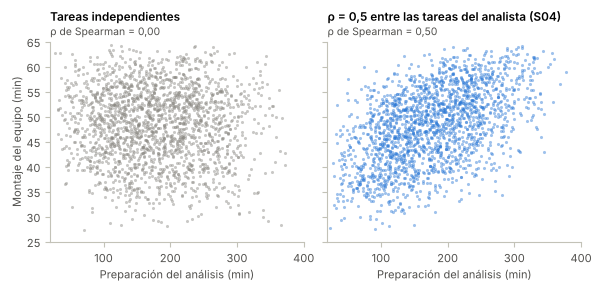

In [7]:
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Inter", "Helvetica", "Arial", "Liberation Sans", "DejaVu Sans"],
    "font.size": 8, "axes.titlesize": 8.5, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "axes.edgecolor": "#c3c2b7", "axes.linewidth": 0.8, "xtick.color": "#c3c2b7", "xtick.labelcolor": "#52514e",
    "ytick.color": "#c3c2b7", "ytick.labelcolor": "#52514e",
    "axes.labelcolor": "#52514e", "figure.facecolor": "white", "axes.facecolor": "white",
})
PANELES = [(independientes, "Tareas independientes", "#898781"),
           (copula, "ρ = 0,5 entre las tareas del analista (S04)", "#2a78d6")]
MUESTRA = 2_000
prep, montaje = (registro.tres_puntos_tareas(ENSAYO, N_SOLUCIONES)[t] for t in ("t_preparacion", "t_montaje"))

fig, ejes = plt.subplots(1, 2, figsize=(5.9, 2.8), layout="constrained", sharex=True, sharey=True)
for eje, (t, titulo, color) in zip(ejes, PANELES):
    eje.scatter(t["t_preparacion"].to_numpy()[:MUESTRA], t["t_montaje"].to_numpy()[:MUESTRA],
                s=5, color=color, alpha=0.45, linewidths=0, rasterized=True)
    rho = co.correlacion_rangos(t[["t_preparacion", "t_montaje"]]).iat[0, 1]
    eje.set_title(titulo, pad=15)
    eje.text(0, 1.02, f"ρ de Spearman = {rho:.2f}".replace(".", ","), transform=eje.transAxes,
             ha="left", va="bottom", fontsize=7.5, color="#52514e")
    eje.set_xlim(prep[0], prep[2])
    eje.set_ylim(montaje[0], montaje[2])
    eje.set_xlabel("Preparación del análisis (min)", labelpad=2)
    for lado in ("top", "right"):
        eje.spines[lado].set_visible(False)
ejes[0].set_ylabel("Montaje del equipo (min)", labelpad=2)
fig.savefig(FIGURA, dpi=300)
plt.show()

## Indicador V2 en una mezcla de ensayos

Una muestra de ejecuciones con la mezcla de demanda del escenario base (columna «Participación en la demanda» de
la hoja «Catálogo»), el número de soluciones sorteado en el rango de la complejidad (S08) y un analista
intermedio, sin preparación ni idoneidad del sistema. Sirve de referencia para el indicador V2 hasta que exista
el dataset v0.1, que cambiará la mezcla de niveles y agregará el alistamiento.

V2 tiene dos partes. Dentro de los grupos del mismo método, número de soluciones, nivel del analista e idoneidad
ejecutada, la correlación de las tareas debe ser la que da la matriz objetivo para el tamaño de cada grupo
(`verificar_por_grupos`); sin agrupar, la mezcla de técnicas la cambia por completo. Y las relaciones de la
estructura (complejidad, número de soluciones, preparación y duración) se miden en todo el dataset y dentro de
cada técnica, sin criterio de aceptación.

In [8]:
COMPLEJIDAD = {"baja": 1, "media": 2, "alta": 3}
ESTRUCTURA = ["complejidad", "n_soluciones", "t_preparacion", "duracion_simulada"]


def mezcla(correlacion, n=N, semilla=SEMILLA):
    """n ejecuciones con la mezcla de demanda, el número de soluciones sorteado en su rango y un analista intermedio."""
    rng = np.random.default_rng(semilla)
    p = catalogo["Participación en la demanda"].astype(float)
    metodos = rng.choice(catalogo.index, size=n, p=p / p.sum())
    partes = []
    for metodo in catalogo.index:
        lo, hi = int(catalogo.at[metodo, "Soluciones mín"]), int(catalogo.at[metodo, "Soluciones máx"])
        soluciones = rng.integers(lo, hi + 1, size=int((metodos == metodo).sum()))
        for n_sol in range(lo, hi + 1):
            t = du.muestrear_ensayo(metodo, n_sol, n=int((soluciones == n_sol).sum()), rng=rng, correlacion=correlacion)
            partes.append(t.assign(metodo=metodo, tecnica=catalogo.at[metodo, "Técnica"],
                                   complejidad=COMPLEJIDAD[catalogo.at[metodo, "Complejidad"]], n_soluciones=n_sol,
                                   nivel_analista="intermedio", idoneidad_ejecutada=False))
    return pd.concat(partes, ignore_index=True)


v2_tareas, v2_estructura, veredictos = [], [], {}
for rho in [None, *RHOS]:
    registros = mezcla(None if rho is None else co.matriz_objetivo(rho))
    meta = co.matriz_objetivo(0.0 if rho is None else rho)
    nombre = "sin" if rho is None else rho
    por_grupos = co.verificar_por_grupos(registros, meta)
    veredictos[nombre] = co.veredicto_v2(por_grupos)
    por_grupos = por_grupos.rename(columns={"obtenida": "Por grupos"})
    sin_agrupar = co.comparar(co.correlacion_rangos(registros[TAREAS]), meta).rename(columns={"obtenida": "Sin agrupar"})
    tabla = por_grupos[["variable_1", "variable_2", "objetivo", "esperada", "Por grupos", "error_estandar", "cumple"]].merge(
        sin_agrupar.drop(columns="diferencia"), on=["variable_1", "variable_2", "objetivo"])
    v2_tareas.append(tabla.assign(**{"ρ": nombre}))
    todo = co.correlacion_rangos(registros[ESTRUCTURA])
    tecnica = co.correlacion_por_grupos(registros, columnas=ESTRUCTURA, por=("tecnica",))
    for i, a in enumerate(ESTRUCTURA):
        for b in ESTRUCTURA[i + 1:]:
            v2_estructura.append({"ρ": nombre, "variable_1": a, "variable_2": b,
                                  "Todo el dataset": todo.at[a, b], "Dentro de cada técnica": tecnica.at[a, b]})
v2_tareas = pd.concat(v2_tareas, ignore_index=True)[["ρ", "variable_1", "variable_2", "objetivo", "esperada",
                                                      "Por grupos", "error_estandar", "cumple", "Sin agrupar"]]
v2_estructura = pd.DataFrame(v2_estructura)
v2_tareas.to_csv(TABLAS / "correlacion_v2_tareas.csv", index=False)
v2_estructura.to_csv(TABLAS / "correlacion_v2_estructura.csv", index=False)
print("Error máximo por grupos:", (v2_tareas["Por grupos"] - v2_tareas["objetivo"]).abs().groupby(v2_tareas["ρ"]).max().round(4).to_dict())
print("Veredicto de V2:", veredictos)
print("Error máximo sin agrupar:", (v2_tareas["Sin agrupar"] - v2_tareas["objetivo"]).abs().groupby(v2_tareas["ρ"]).max().round(3).to_dict())
v2_tareas[v2_tareas["ρ"].eq(0.5)].round(3)

Error máximo por grupos: {0.3: 0.004, 0.5: 0.0033, 0.7: 0.0028, 'sin': 0.0037}
Veredicto de V2: {'sin': 'cumple', 0.3: 'cumple', 0.5: 'cumple', 0.7: 'cumple'}
Error máximo sin agrupar: {0.3: 0.884, 0.5: 1.04, 0.7: 1.197, 'sin': 0.648}


,ρ,variable_1,variable_2,objetivo,esperada,Por grupos,error_estandar,cumple,Sin agrupar
12,0.5,t_preparacion,t_montaje,0.5,0.5,0.502,0.002,True,0.542
13,0.5,t_preparacion,t_corrida,0.0,0.0,0.003,0.002,True,0.582
14,0.5,t_preparacion,t_procesamiento,0.5,0.5,0.502,0.002,True,-0.131
15,0.5,t_montaje,t_corrida,0.0,0.0,-0.001,0.002,True,0.217
16,0.5,t_montaje,t_procesamiento,0.5,0.5,0.502,0.002,True,-0.540
17,0.5,t_corrida,t_procesamiento,0.0,0.0,-0.003,0.002,True,-0.029


In [9]:
v2_estructura.pivot_table(index=["variable_1", "variable_2"], columns="ρ", sort=False,
                          values=["Todo el dataset", "Dentro de cada técnica"]).round(3)

Todo el dataset                       \
ρ                                           sin    0.3    0.5    0.7   
variable_1    variable_2                                               
complejidad   n_soluciones                0.905  0.905  0.905  0.905   
              t_preparacion               0.105  0.107  0.107  0.107   
              duracion_simulada          -0.069 -0.062 -0.059 -0.056   
n_soluciones  t_preparacion               0.220  0.220  0.220  0.221   
              duracion_simulada           0.000  0.003  0.005  0.006   
t_preparacion duracion_simulada           0.863  0.873  0.879  0.886   

                                Dentro de cada técnica                       
ρ                                                  sin    0.3    0.5    0.7  
variable_1    variable_2                                                     
complejidad   n_soluciones                       0.818  0.818  0.818  0.818  
              t_preparacion                      0.608  0.611  0.610  0.610  
              duracion_simulada                  0.741  0.722  0.709  0.697  
n_soluciones  t_preparacion                      0.716  0.716  0.716  0.715  
              duracion_simulada                  0.776  0.747  0.730  0.715  
t_preparacion duracion_simulada                  0.903  0.915  0.923  0.932

## Tolerancia de V2 en un dataset chico

En el dataset los grupos son mucho más chicos que en la mezcla anterior: hay varios niveles de analista y la
idoneidad del sistema solo se ejecuta a veces. Con pocos registros por grupo, la correlación de rangos sale más cerca
de cero que la objetivo (con ρ = 0,5 y 10 registros, en promedio 0,458; Moran, 1948), así que una tolerancia fija
fallaría con datos correctos. `verificar_por_grupos` compara con la esperada para el tamaño de cada grupo y acepta
una diferencia de hasta cinco errores estándar. El error estándar sale de la varianza de la correlación de rangos
de n pares independientes, 1/(n − 1) (Xu et al., 2010, ec. 20 con ρ = 0): es exacto en los pares que deben ser
independientes y mayor que el real en los correlacionados (entre un 20 y un 30 % con ρ = 0,5), y no depende de cuántos
grupos haya ni de cuán distintos sean sus tamaños. `veredicto_v2` resume los pares: «cumple», «no cumple» o «sin datos suficientes», si algún par no tiene
ningún grupo de al menos 10 registros o, cabiendo en su tolerancia, tiene tan pocos que no vería una correlación del
tamaño de la de S04: la ve si siete errores estándar no pasan de la correlación esperada con ese ρ, y entonces la
detecta el 97,7 % de las veces.

La prueba repite 100 veces un dataset de 2 000 ejecuciones (unas 7 semanas del escenario base, que pide 15 323
ensayos al año) con la mezcla de demanda; el número de soluciones sorteado en su rango; el nivel del analista
sorteado entre los analistas calificados para el método (hoja «Analistas»), y la preparación y la idoneidad del
sistema en el 30 % de los ensayos de HPLC y GC, con los tres puntos de ensayo de `tests/test_duraciones.py`. Esa
frecuencia y esos tres puntos son valores de ensayo: los reales están pendientes (sección 1.10). Cada réplica se
genera con ρ = 0,5, que es la objetivo, y con ρ = 0,4 y 0,3, que no lo son, y se verifica siempre contra la
objetivo. Después, la misma prueba con datos correctos en datasets de 500, 1 000 y 1 500 ejecuciones muestra
desde qué tamaño se pueden evaluar todos los pares, y la última, con S04 = 0,3 (la propuesta si queda λ = 1;
sección 2.7) en datasets de 2 000 y 3 500 ejecuciones, cuánto más hace falta cuando la correlación que hay que ver
es más chica.

In [10]:
analistas = parametros.cargar_hoja("Analistas").set_index("ID")
NIVELES = {m: analistas.loc[analistas[m].eq(1), "Nivel"].value_counts(normalize=True) for m in catalogo.index}
SISTEMA_DE_ENSAYO = {"prep_sistema": (60.0, 90.0, 150.0), "idoneidad": (100.0, 150.0, 200.0)}
P_IDONEIDAD, N_CHICO, REPLICAS = 0.3, 2_000, 100


def dataset_chico(correlacion, semilla, n=N_CHICO):
    """n ejecuciones con la mezcla de demanda, niveles de analista y la idoneidad de ensayo en HPLC y GC."""
    rng = np.random.default_rng(semilla)
    p = catalogo["Participación en la demanda"].astype(float)
    metodos = rng.choice(catalogo.index, size=n, p=p / p.sum())
    partes = []
    for metodo in catalogo.index:
        cuantos = int((metodos == metodo).sum())
        if cuantos == 0:
            continue
        lo, hi = int(catalogo.at[metodo, "Soluciones mín"]), int(catalogo.at[metodo, "Soluciones máx"])
        niveles = NIVELES[metodo]
        idoneidad = catalogo.at[metodo, "Requiere idoneidad"] == "Sí"
        tabla = pd.DataFrame({"n_soluciones": rng.integers(lo, hi + 1, size=cuantos),
                              "nivel_analista": rng.choice(niveles.index, size=cuantos, p=niveles.to_numpy()),
                              "idoneidad_ejecutada": idoneidad & (rng.random(cuantos) < P_IDONEIDAD)})
        for (n_sol, nivel, con_sistema), grupo in tabla.groupby(["n_soluciones", "nivel_analista", "idoneidad_ejecutada"]):
            t = du.muestrear_ensayo(metodo, int(n_sol), n=len(grupo), rng=rng, nivel=nivel, correlacion=correlacion,
                                    **(SISTEMA_DE_ENSAYO if con_sistema else {}))
            partes.append(t.assign(metodo=metodo, n_soluciones=n_sol, nivel_analista=nivel,
                                   idoneidad_ejecutada=con_sistema))
    return pd.concat(partes, ignore_index=True)


def prueba(ejecuciones, datos, rho, k, s04=0.5):
    v = co.verificar_por_grupos(dataset_chico(co.matriz_objetivo(rho), SEMILLA + k, n=ejecuciones), co.matriz_objetivo(s04))
    evaluados = v[v["cumple"].notna()]
    analista = evaluados[evaluados["objetivo"].gt(0)]
    return {"S04": s04, "Ejecuciones": ejecuciones, "Datos": datos, "Réplica": k, "Pares": len(v),
            "Pares evaluados": len(evaluados),
            "Grupos por par (mínimo)": int(evaluados["grupos"].min()) if len(evaluados) else 0,
            "Grupos por par (máximo)": int(evaluados["grupos"].max()) if len(evaluados) else 0,
            "Mayor |diferencia| / error estándar": float((evaluados["diferencia"] / evaluados["error_estandar"]).abs().max()),
            "Tolerancia en los pares del analista (mínima)": float(analista["tolerancia"].min()),
            "Tolerancia en los pares del analista (máxima)": float(analista["tolerancia"].max()),
            "Pasa con tolerancia fija de 0,05": bool((evaluados["obtenida"] - evaluados["objetivo"]).abs().max() <= 0.05),
            "Veredicto": co.veredicto_v2(v)}


DATOS = {"ρ = 0,5 (la objetivo)": 0.5, "ρ = 0,4 (otra)": 0.4, "ρ = 0,3 (otra)": 0.3}
filas = [prueba(N_CHICO, datos, rho, k) for k in range(REPLICAS) for datos, rho in DATOS.items()]
filas += [prueba(n, "ρ = 0,5 (la objetivo)", 0.5, k) for n in (500, 1_000, 1_500) for k in range(REPLICAS)]
filas += [prueba(n, "ρ = 0,3 (la objetivo)", 0.3, k, s04=0.3) for n in (2_000, 3_500) for k in range(REPLICAS)]
tolerancia = pd.DataFrame(filas)
tolerancia.to_csv(TABLAS / "correlacion_v2_tolerancia.csv", index=False)
(tolerancia.groupby(["S04", "Ejecuciones", "Datos"], sort=False)
 .agg(**{"Datasets": ("Réplica", "size"),
         "Cumple": ("Veredicto", lambda v: int(v.eq("cumple").sum())),
         "No cumple": ("Veredicto", lambda v: int(v.eq("no cumple").sum())),
         "Sin datos suficientes": ("Veredicto", lambda v: int(v.eq("sin datos suficientes").sum())),
         "Mayor |diferencia| / error estándar": ("Mayor |diferencia| / error estándar", "max"),
         "Tolerancia del analista (mín.)": ("Tolerancia en los pares del analista (mínima)", "min"),
         "Tolerancia del analista (máx.)": ("Tolerancia en los pares del analista (máxima)", "max"),
         "Pasa con 0,05 fija": ("Pasa con tolerancia fija de 0,05", "sum")})
 .round(3))

Datasets  Cumple  No cumple  \
S04 Ejecuciones Datos                                                
0.5 2000        ρ = 0,5 (la objetivo)       100     100          0   
                ρ = 0,4 (otra)              100      62         38   
                ρ = 0,3 (otra)              100       0        100   
    500         ρ = 0,5 (la objetivo)       100       0          0   
    1000        ρ = 0,5 (la objetivo)       100       0          0   
    1500        ρ = 0,5 (la objetivo)       100     100          0   
0.3 2000        ρ = 0,3 (la objetivo)       100       0          0   
    3500        ρ = 0,3 (la objetivo)       100     100          0   

                                       Sin datos suficientes  \
S04 Ejecuciones Datos                                          
0.5 2000        ρ = 0,5 (la objetivo)                      0   
                ρ = 0,4 (otra)                             0   
                ρ = 0,3 (otra)                             0   
    500         ρ = 0,5 (la objetivo)                    100   
    1000        ρ = 0,5 (la objetivo)                    100   
    1500        ρ = 0,5 (la objetivo)                      0   
0.3 2000        ρ = 0,3 (la objetivo)                    100   
    3500        ρ = 0,3 (la objetivo)                      0   

                                       Mayor |diferencia| / error estándar  \
S04 Ejecuciones Datos                                                        
0.5 2000        ρ = 0,5 (la objetivo)                                3.621   
                ρ = 0,4 (otra)                                       7.056   
                ρ = 0,3 (otra)                                      11.626   
    500         ρ = 0,5 (la objetivo)                                3.396   
    1000        ρ = 0,5 (la objetivo)                                3.547   
    1500        ρ = 0,5 (la objetivo)                                3.020   
0.3 2000        ρ = 0,3 (la objetivo)                                3.194   
    3500        ρ = 0,3 (la objetivo)                                2.997   

                                       Tolerancia del analista (mín.)  \
S04 Ejecuciones Datos                                                   
0.5 2000        ρ = 0,5 (la objetivo)                           0.115   
                ρ = 0,4 (otra)                                  0.115   
                ρ = 0,3 (otra)                                  0.115   
    500         ρ = 0,5 (la objetivo)                           0.279   
    1000        ρ = 0,5 (la objetivo)                           0.173   
    1500        ρ = 0,5 (la objetivo)                           0.135   
0.3 2000        ρ = 0,3 (la objetivo)                           0.115   
    3500        ρ = 0,3 (la objetivo)                           0.086   

                                       Tolerancia del analista (máx.)  \
S04 Ejecuciones Datos                                                   
0.5 2000        ρ = 0,5 (la objetivo)                           0.288   
                ρ = 0,4 (otra)                                  0.288   
                ρ = 0,3 (otra)                                  0.288   
    500         ρ = 0,5 (la objetivo)                           0.327   
    1000        ρ = 0,5 (la objetivo)                           0.182   
    1500        ρ = 0,5 (la objetivo)                           0.342   
0.3 2000        ρ = 0,3 (la objetivo)                           0.117   
    3500        ρ = 0,3 (la objetivo)                           0.206   

                                       Pasa con 0,05 fija  
S04 Ejecuciones Datos                                      
0.5 2000        ρ = 0,5 (la objetivo)                   5  
                ρ = 0,4 (otra)                          0  
                ρ = 0,3 (otra)                          0  
    500         ρ = 0,5 (la objetivo)                  12  
    1000        ρ = 0,5 (la objetivo)                  38  
    1500        ρ = 0,5 (la objeti